# Phase 4: the training dataset

A surrogate (Phase 5) is a fast function fitted to examples. The examples come from here: each one is a complete engine *designed* by the coupled physics model of Phase 3, checked mechanically, and run at four operating points. Three ideas matter more than any code:

1. **Cover the design space evenly.** Designs come from a scrambled **Sobol sequence**, a *low-discrepancy* sequence: unlike independent random draws it leaves no big holes and no clumps, so 2000 points cover a 7-D box about as well as many more random ones.
2. **Keep the failures.** About two thirds of the box cannot be built as this engine family (the compressor can't reach the pressure ratio, the turbine can't be sized, ...). Those records stay in the data with a reason: a surrogate that never sees them can't learn where the feasible region ends.
3. **Freeze the test set first.** 15 % of the design ids were set aside by a seeded permutation *before any design was evaluated*. They are never used for training or tuning, so Phase 5's test error is an honest estimate.

This notebook explores the **pilot**: the first 256 designs of the Sobol sequence, run in the cloud container. The full 2000-design run happens on the user's laptop after the wall-time estimate.

> Preliminary design only, not manufacturing-ready: everything here is a meanline/0-D model.

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(); os.chdir(ROOT)
warnings.filterwarnings('ignore')
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
INK, MUTED, GRID = '#1f1f1e', '#6b6a63', '#e4e3dd'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'font.size': 10})
P4 = ROOT / 'validation' / 'phase4'
D = pd.read_csv(P4 / 'pilot_phase4_v1_designs.csv'); P = pd.read_csv(P4 / 'pilot_phase4_v1_points.csv')
ok = D[D.status == 'ok']
print(f'{len(D)} designs, {len(ok)} designed engines, {int(ok.feasible.astype(bool).sum())} mechanically feasible')

256 designs, 92 designed engines, 3 mechanically feasible


## 1. Where in the box do designs work?
Each dot is one sampled design, plotted on two of its seven variables. Grey: design mode failed. Colour: designed. A failure is not noise: it marks a region where this engine family has no solution. In the pilot (median values per failure type): low shaft speed with high PR fails because no impeller size reaches the PR before choking (median ~80-95 krpm); high speed with a large mass flow fails because the PR is reached only with an impeller exit *smaller* than its own inlet (`r2_below_inducer`, median ~160 krpm, 0.8 kg/s). Designed engines sit in between (median ~130 krpm, 0.3 kg/s).

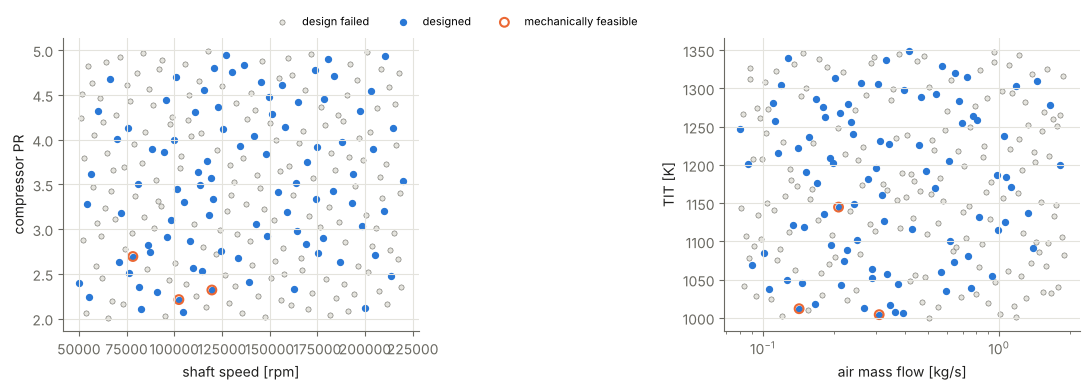

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (x, y, xl, yl) in zip(axes, [('in_n_rpm', 'in_pr_c', 'shaft speed [rpm]', 'compressor PR'),
                                     ('in_W_air_kg_s', 'in_tit_K', 'air mass flow [kg/s]', 'TIT [K]')]):
    f = D[D.status != 'ok']
    ax.scatter(f[x], f[y], s=14, color=GRID, edgecolor=MUTED, linewidth=0.4, label='design failed')
    ax.scatter(ok[x], ok[y], s=18, color=SERIES[0], label='designed')
    feas = ok[ok.feasible.astype(bool)]
    ax.scatter(feas[x], feas[y], s=40, facecolor='none', edgecolor=SERIES[1], linewidth=1.5, label='mechanically feasible')
    ax.set(xlabel=xl, ylabel=yl)
axes[1].set_xscale('log'); axes[0].legend(frameon=False, fontsize=8, loc='lower center', bbox_to_anchor=(1.1, 1.0), ncol=3)
plt.tight_layout(); plt.show()

## 2. Why designs fail (design mode)
- `design_compressor_r2_below_inducer`: the PR is reached only with an impeller exit radius smaller than the inducer tip, which is not a centrifugal compressor.
- `design_compressor_pr_not_reached_choke_*`: no impeller size reaches the PR before the flow chokes (the local Mach number reaches 1) in the impeller exit or the diffuser.
- `design_compressor_choke_impeller_exit`: the sized compressor chokes at its own design point.
- `design_turbine`: no turbine geometry delivers the compressor power with the chosen stage coefficients (flow coefficient, loading, reaction).

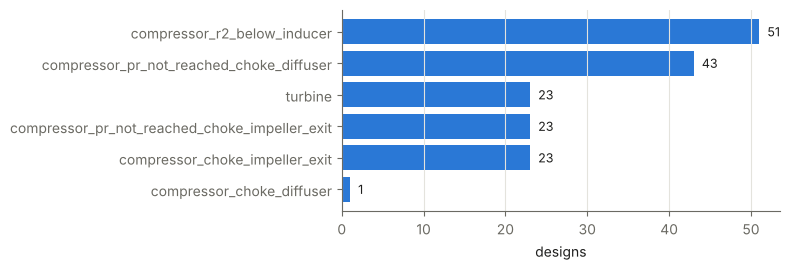

In [3]:
fr = D.loc[D.status != 'ok', 'failure_reason'].str.replace(r':.*', '', regex=True).value_counts()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(fr.index.str.replace('design_', ''), fr.values, color=SERIES[0]); ax.invert_yaxis()
ax.set(xlabel='designs'); ax.grid(axis='y', visible=False)
for i, v in enumerate(fr.values): ax.text(v + 1, i, str(v), va='center', color=INK, fontsize=9)
plt.tight_layout(); plt.show()

## 3. Mechanical feasibility: the turbine blade root is the bottleneck
A spinning blade pulls on its root. For a blade of constant section the root stress is $\sigma_c = K\rho\Omega^2 A/(2\pi)$: density x speed² x annulus area, the **AN²** proxy. The material must carry 1.5 x that stress (plus gas bending) for 100 h at the blade's metal temperature without creep rupture. Left: required stress vs what IN-713C can carry; points above the diagonal fail. Right: impeller tip speed, which correlates strongly with PR (a centrifugal compressor's pressure rise comes from tip speed).

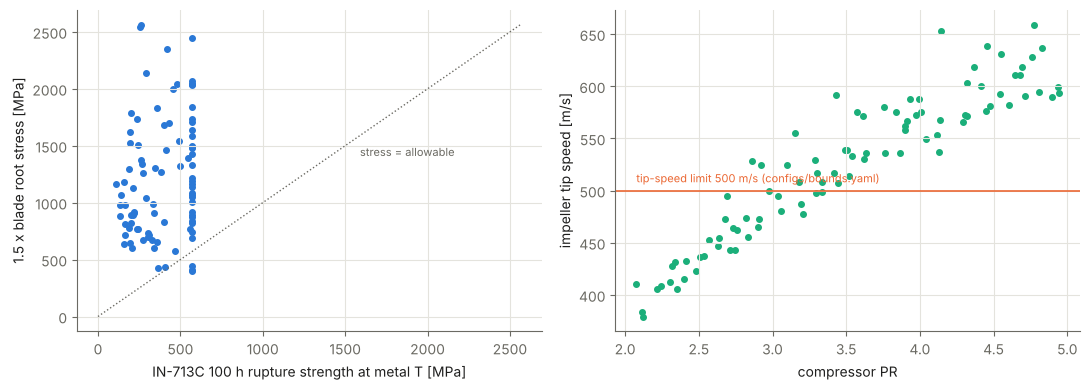

corr(PR, tip speed) = 0.94


,infeasible designs
active_constraints,
AN2;tip_speed,51
AN2,29
AN2;TIT_ngv_above_material_data;tip_speed,5
AN2;TIT_ngv_above_material_data,2
tip_speed,2


In [4]:
from turboml.config import load_config
lim = load_config().constraints.max_impeller_tip_speed_m_s
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
req = 1.5 * (ok.creep_in713c_rotor_stress_centrifugal_Pa + ok.creep_in713c_rotor_stress_gas_bending_Pa) / 1e6
allow = ok.creep_in713c_rotor_allowable_Pa / 1e6
axes[0].scatter(allow, req, s=16, color=SERIES[0]); m = float(np.nanmax([req.max(), allow.max()]))
axes[0].plot([0, m], [0, m], color=MUTED, lw=1, ls=':'); axes[0].text(0.62 * m, 0.55 * m, 'stress = allowable', color=MUTED, fontsize=8)
axes[0].set(xlabel='IN-713C 100 h rupture strength at metal T [MPa]', ylabel='1.5 x blade root stress [MPa]')
axes[1].scatter(ok.in_pr_c, ok.impeller_tip_speed_m_s, s=16, color=SERIES[2]); axes[1].axhline(lim, color=SERIES[1], lw=1.2)
axes[1].text(ok.in_pr_c.min(), lim + 8, f'tip-speed limit {lim:.0f} m/s (configs/bounds.yaml)', color=SERIES[1], fontsize=8)
axes[1].set(xlabel='compressor PR', ylabel='impeller tip speed [m/s]')
plt.tight_layout(); plt.show()
print('corr(PR, tip speed) =', round(ok.in_pr_c.corr(ok.impeller_tip_speed_m_s), 2))
ok.loc[~ok.feasible.astype(bool), 'active_constraints'].value_counts().rename('infeasible designs').to_frame()

### The creep data behind the check
Rupture strength (stress that breaks a test bar in 100 h or 1000 h) for the two cast nickel alloys, from NiDI No. 393 Tables 9 and 10. Strength falls steeply with temperature; above the last tabulated temperature we do **not** extrapolate (the design is labelled `..._above_material_data`).

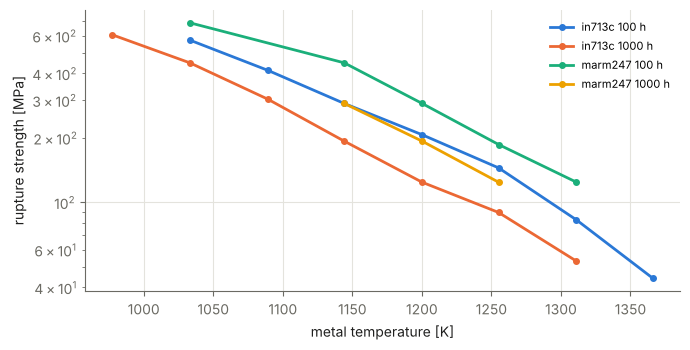

In [5]:
r = pd.read_csv('validation/cases/ni393_cast_rupture.csv', comment='#')
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, ((a, life), g) in enumerate(r.groupby(['alloy', 'life_h'])):
    ax.plot(g.T_C + 273.15, g.strength_ksi * 6.894757, 'o-', color=SERIES[i], ms=4, label=f'{a} {life:.0f} h')
ax.set(xlabel='metal temperature [K]', ylabel='rupture strength [MPa]', yscale='log'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Nozzle guide vanes and the missing pattern factor
The combustor exit is not uniform: hot streaks hit some vanes at $T_{NGV} = TIT + PF\,(TIT - T_3)$, PF = pattern factor. We found no citable PF range for micro combustors, so the dataset stores **PF_max**, the largest pattern factor each design's vanes survive. Once PF is sourced, feasibility is recomputed from this column without re-running anything. PF_max < 0 means the vanes fail even with a perfectly uniform combustor exit. Note: the MAR-M 247 rupture data stop at 1900 F (1311 K), below IN-713C's 2000 F (1366 K), so above ~1311 K the 'premium' alloy cannot be checked at all (`above_material_data`).

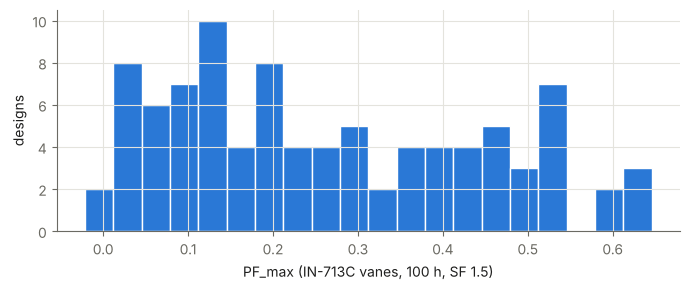

quantiles: {0.1: 0.043, 0.5: 0.238, 0.9: 0.517} | PF_max < 0 (vanes fail even at PF = 0): 2


In [6]:
pf = ok.creep_in713c_ngv_pf_max.astype(float)
fig, ax = plt.subplots(figsize=(7, 3)); ax.hist(pf.dropna(), bins=20, color=SERIES[0], edgecolor='white')
ax.set(xlabel='PF_max (IN-713C vanes, 100 h, SF 1.5)', ylabel='designs'); plt.tight_layout(); plt.show()
print('quantiles:', pf.quantile([0.1, 0.5, 0.9]).round(3).to_dict(), '| PF_max < 0 (vanes fail even at PF = 0):', int((pf < 0).sum()))

## 5. Off-design points
Every designed engine is also run at M0.5 / 3 km (design speed), 80 % speed and idle (35 % speed). Points that don't converge are kept with a reason. `choke_compressor_inducer` at cruise means the ram-compressed, denser inlet air pushes the compressor inlet to Mach 1, which happens when the design point is already close to inducer choke.

In [7]:
g = P[P.design_id.isin(ok.design_id)]
pd.DataFrame({'converged': g.groupby('point').converged.sum().astype(int), 'of': g.groupby('point').size(),
              'failure reasons': g[~g.converged.astype(bool)].groupby('point').failure_reason.agg(lambda s: dict(s.value_counts()))}).fillna('')

,converged,of,failure reasons
point,,,
cruise_M05_3km,90,92,{'choke_compressor_inducer': 2}
design,92,92,
idle_35,92,92,
part_speed_80,92,92,


## 6. How the compressor calibration uncertainty enters
The KJ-66 compressor calibration (slip correction Δσ, diffuser friction Cf) has a statistical uncertainty band, but the model also has *form* error. We widened the band by a common factor k until at least 95 % of the held-out measured points fell inside the model's prediction envelope. 20 % of the designs sample (Δσ, Cf) uniformly in that inflated band, so the surrogate sees the calibration spread.

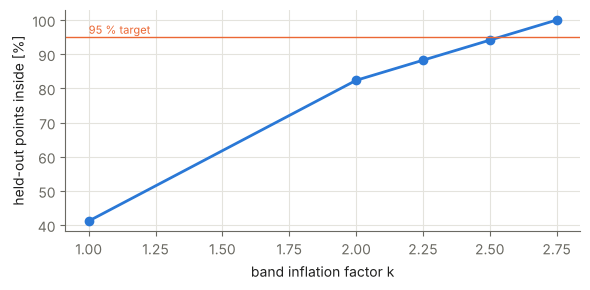

,k,coverage,n_failed_predictions
0,1.00,0.411765,0
1,2.00,0.823529,0
2,2.25,0.882353,0
3,2.50,0.941176,0
4,2.75,1.000000,0


In [8]:
b = pd.read_csv(P4 / 'compressor_band_inflation.csv')
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(b.k, 100 * b.coverage, 'o-', color=SERIES[0])
ax.axhline(95, color=SERIES[1], lw=1); ax.text(b.k.min(), 96, '95 % target', color=SERIES[1], fontsize=8)
ax.set(xlabel='band inflation factor k', ylabel='held-out points inside [%]'); plt.tight_layout(); plt.show()
b[['k', 'coverage', 'n_failed_predictions']]

## 7. Cost and profiling
Profiling showed that most of the time went into the vaneless-diffuser march, where every step solved continuity from scratch. A warm-started Newton step (same equations, identical results) made the whole engine model 3-4 times faster.

,bracketed [s],Newton [s],speedup
design_engine_s,2.970,0.904,3.3
off_design_n100_alt3000_M0.5_s,3.197,0.954,3.4
off_design_n80_alt0_M0.0_s,2.638,0.708,3.7
off_design_n35_alt0_M0.0_s,4.105,0.951,4.3


max relative output difference: 3.0347058199708954e-11


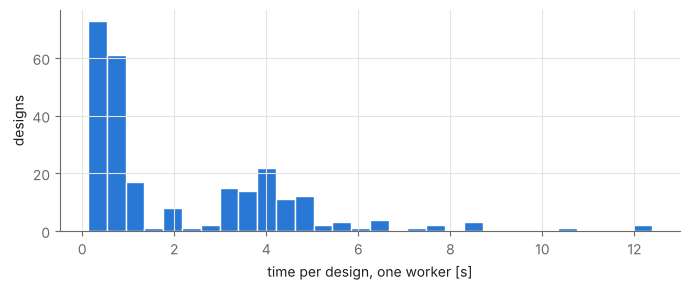

In [9]:
prof = yaml.safe_load((P4 / 'profiling.yaml').read_text())
display(pd.DataFrame({'bracketed [s]': prof['wall_s_bracketed_solver'], 'Newton [s]': prof['wall_s_newton_warm_start'],
                      'speedup': prof['speedup']}))
print('max relative output difference:', prof['max_rel_diff_outputs'])
fig, ax = plt.subplots(figsize=(7, 3)); ax.hist(D.time_s, bins=30, color=SERIES[0], edgecolor='white')
ax.set(xlabel='time per design, one worker [s]', ylabel='designs'); plt.tight_layout(); plt.show()

## 8. Physics cross-check
A random 2 % of the designed engines are re-run as plain 0-D cycles in pyCycle-CEA (NASA's cycle code with full chemical-equilibrium gas properties), using the efficiencies our coupled model produced. More than 1 % difference in thrust or TSFC flags a design; more than 5 % flagged stops the pipeline.

In [10]:
yaml.safe_load((P4 / 'crosscheck_phase4_v1.yaml').read_text())

{'designed_engines': 92,
 'checked': 2,
 'fraction': 0.02,
 'seed': 20261027,
 'simple_vs_pycycle': {'flagged': 0, 'flagged_frac': 0.0, 'gate_passed': True},
 'coupled_vs_pycycle': {'flagged': 0,
  'flagged_frac': 0.0,
  'gate_passed': True,
  'max_abs_Fn_pct': 0.0386,
  'max_abs_TSFC_pct': 0.0669},
 'secondary_dFn_over_Fg_max_abs': 0.00039,
 'design_ids': [169, 245]}

## What this means for Phase 5
- With the box as sampled, only ~1 in 30 designs is both buildable and mechanically feasible. A surrogate needs enough feasible examples, so the sampling parametrization (speed tied to the thrust trend) and the creep settings (taper factor, tip-speed limit) are decisions for the user before the full run.
- Turbine efficiency at micro scale is still unvalidated, and is flagged on every design.